<a href="https://colab.research.google.com/github/veorte/registros/blob/main/Actividad7PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 7**
Análisis de Componentes Principales (PCA)

---

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


*   NOMBRE: Verónica Ortega López, Manuel Olmos Antillón, Brayan Ortega Armendáriz
*   MATRÍCULA: A01841596, A01750748, A01561888

En esta actividad trabajarás con el archivo `automobile_dataset.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de automóviles, disponible en el repositorio UCI Machine Learning.

Los datos fueron recopilados para analizar diferentes aspectos de los vehículos y sus precios, e incluyen información sobre el fabricante, tipo de motor, dimensiones, peso, rendimiento de combustible y otras especificaciones técnicas. Los indicadores incluidos son:

* `symboling`: Nivel de riesgo del seguro del automóvil, de -3 (bajo riesgo) a +3 (alto riesgo)
* `normalized_losses`: Pérdidas normalizadas del seguro (valor numérico de la aseguradora, algunas veces faltante)
* `make`: Marca del automóvil (por ejemplo, Audi, BMW, Honda)
* `fuel_type`: Tipo de combustible (gasolina o diésel)
* `aspiration`: Tipo de aspiración del motor (normal o turbo)
* `num_doors`: Número de puertas del automóvil (dos o cuatro)
* `body_style`: Estilo de carrocería (sedán, hatchback, wagon, hardtop, convertible)
* `drive_wheels`: Tipo de tracción (fwd: delantera, rwd: trasera, 4wd: en las cuatro ruedas)
* `engine_location`: Ubicación del motor (delantero o trasero)
* `wheel_base`: Distancia entre ejes (en pulgadas)
* `length`: Largo total del automóvil (en pulgadas)
* `width`: Ancho total del automóvil (en pulgadas)
* `height`: Altura total del automóvil (en pulgadas)
* `curb_weight`: Peso del automóvil sin carga (en libras)
* `engine_type`: Tipo de motor (OHV, OHC, DOHC, etc.)
* `num_cylinders`: Número de cilindros del motor
* `engine_size`: Tamaño del motor (en cc)
* `fuel_system`: Sistema de combustible (por ejemplo, mpfi, 2bbl, 4bbl)
* `bore`: Diámetro del cilindro (en pulgadas)
* `stroke`: Carrera del pistón (en pulgadas)
* `compression_ratio`: Relación de compresión del motor
* `horsepower`: Potencia del motor (en caballos de fuerza)
* `peak_rpm`: Revoluciones máximas por minuto
* `city_mpg`: Rendimiento de combustible en ciudad (millas por galón)
* `highway_mpg`: Rendimiento de combustible en carretera (millas por galón)
* `price`: Precio del automóvil (en dólares estadounidenses) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [2]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

1. Descarga el archivo: `automobile_dataset.csv` y guarda, en un dataframe (`cars_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Al revisar los primeros registros, notarás que la columna `normalized_losses` contiene el símbolo `?`. Esto sugiere que se utilizó para indicar valores faltantes. Identifica todas las columnas que presentan este símbolo.
* Sustituye el símbolo `?` por valores faltantes (`NaN`) y convierte las columnas al tipo de dato adecuado. Esto es necesario porque la presencia del símbolo pudo haber hecho que pandas las interpretara como object, aunque en realidad no lo fueran.

In [7]:
cars_df = pd.read_csv('automobile_dataset.csv')

print(cars_df.shape)
display(cars_df.head())

(205, 26)


,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450


In [8]:
cars_df.info()

print(cars_df.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    int64  
 16  engine_size        205 non

Inicialmente tenemos 13 columnas numéricas y 13 de tipo object.

In [9]:
for col in cars_df.columns:
    cantidad = (cars_df[col] == '?').sum()

    if cantidad > 0:
        print(f'{col}: {cantidad}')

normalized_losses: 41
bore: 4
stroke: 4
horsepower: 2
peak_rpm: 2


In [10]:
cars_df.replace('?', np.nan, inplace=True)

columnas_numericas = [
    'normalized_losses',
    'bore',
    'stroke',
    'horsepower',
    'peak_rpm'
]

for col in columnas_numericas:
    cars_df[col] = pd.to_numeric(
        cars_df[col],
        errors='coerce'
    )

cars_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    int64  
 16  engine_size        205 non

# Análisis exploratorio de datos (univariado)

2. Antes de iniciar con el análisis univariado, verifica si hay registros duplicados e imprime el porcentaje de faltantes por columna.
* Obtén las estadísticas descriptivas, separado las numéricas (incluye asimetría y curtosis) y las categóricas (incluye tablas de frecuencias).
* Genera histogramas para las numéricas y diagramas de barras para las categóricas.

In [11]:
duplicados = cars_df.duplicated().sum()

print('Registros duplicados:', duplicados)


Registros duplicados: 0


No tenemos registros duplicados.

In [12]:
faltantes = pd.DataFrame({
    'Cantidad': cars_df.isnull().sum(),
    'Porcentaje': cars_df.isnull().mean() * 100
})

display(faltantes[faltantes['Cantidad'] > 0].round(2))

,Cantidad,Porcentaje
normalized_losses,41,20.00
bore,4,1.95
stroke,4,1.95
horsepower,2,0.98
peak_rpm,2,0.98


In [13]:
num_df = cars_df.select_dtypes(include='number')

estadisticas_num = num_df.describe().T

estadisticas_num['asimetria'] = num_df.skew()
estadisticas_num['curtosis'] = num_df.kurt()

display(estadisticas_num.round(2))

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
symboling,205.0,0.83,1.25,-2.00,0.00,1.00,2.00,3.00,0.21,-0.68
normalized_losses,164.0,122.00,35.44,65.00,94.00,115.00,150.00,256.00,0.77,0.53
wheel_base,205.0,98.76,6.02,86.60,94.50,97.00,102.40,120.90,1.05,1.02
length,205.0,174.05,12.34,141.10,166.30,173.20,183.10,208.10,0.16,-0.08
width,205.0,65.91,2.15,60.30,64.10,65.50,66.90,72.30,0.90,0.70
height,205.0,53.72,2.44,47.80,52.00,54.10,55.50,59.80,0.06,-0.44
curb_weight,205.0,2555.57,520.68,1488.00,2145.00,2414.00,2935.00,4066.00,0.68,-0.04
num_cylinders,205.0,4.38,1.08,2.00,4.00,4.00,4.00,12.00,2.82,13.71
engine_size,205.0,126.91,41.64,61.00,97.00,120.00,141.00,326.00,1.95,5.31
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.59,3.94,0.02,-0.83


In [14]:
cat_df = cars_df.select_dtypes(include='object')

display(cat_df.describe().T)

for col in cat_df.columns:
    print(f'\nVariable: {col}')
    print(cars_df[col].value_counts(dropna=False))

,count,unique,top,freq
make,205,22,toyota,32
fuel_type,205,2,gas,185
aspiration,205,2,std,168
num_doors,205,2,four,116
body_style,205,5,sedan,96
drive_wheels,205,3,fwd,120
engine_location,205,2,front,202
engine_type,205,7,ohc,148
fuel_system,205,8,mpfi,94



Variable: make
make
toyota           32
nissan           18
mazda            17
mitsubishi       13
honda            13
subaru           12
volkswagen       12
volvo            11
peugot           11
dodge             9
mercedes-benz     8
bmw               8
audi              7
plymouth          7
saab              6
porsche           5
isuzu             4
alfa-romero       3
chevrolet         3
jaguar            3
renault           2
mercury           1
Name: count, dtype: int64

Variable: fuel_type
fuel_type
gas       185
diesel     20
Name: count, dtype: int64

Variable: aspiration
aspiration
std      168
turbo     37
Name: count, dtype: int64

Variable: num_doors
num_doors
four    116
two      89
Name: count, dtype: int64

Variable: body_style
body_style
sedan          96
hatchback      70
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64

Variable: drive_wheels
drive_wheels
fwd    120
rwd     76
4wd      9
Name: count, dtype: int64

Variable: engine

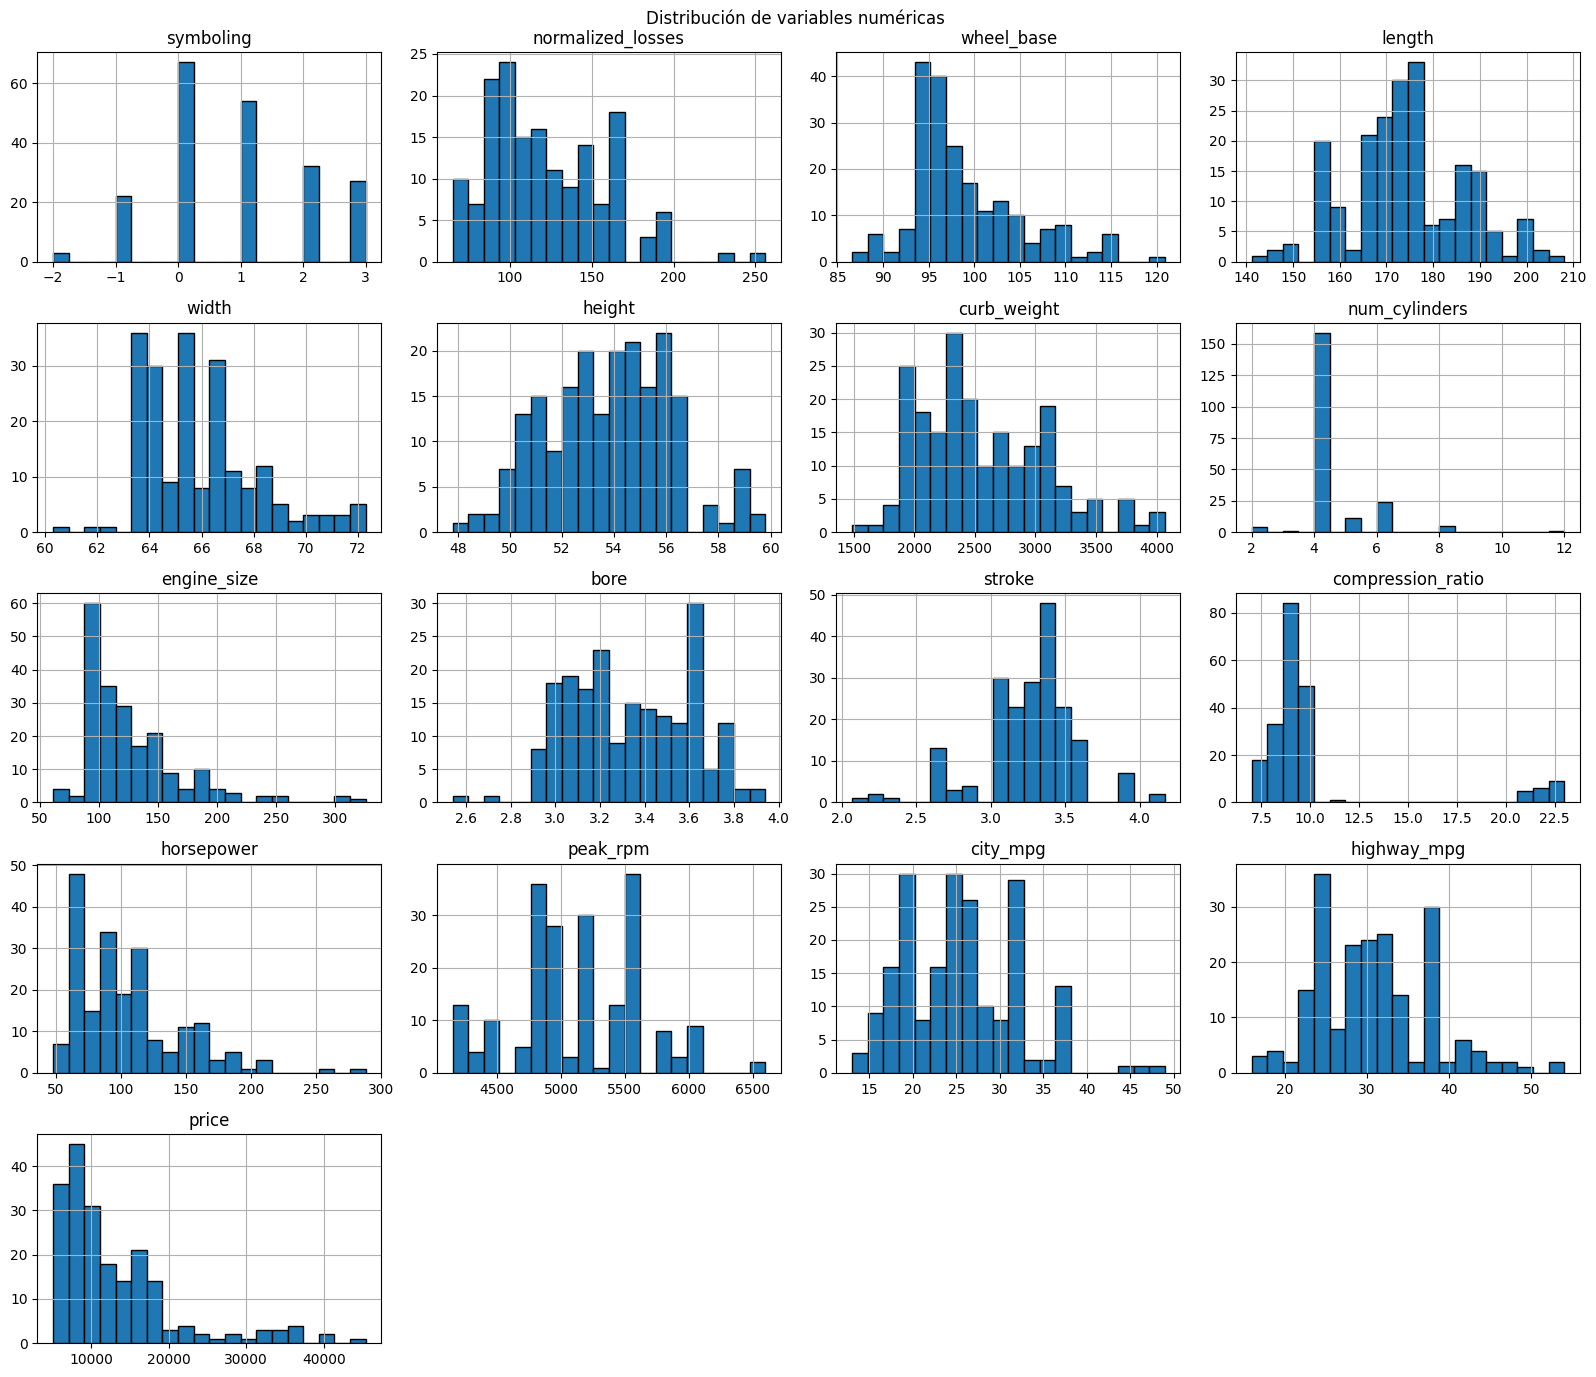

In [15]:
num_df.hist(
    figsize=(16, 14),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Distribución de variables numéricas')
plt.tight_layout()
plt.show()

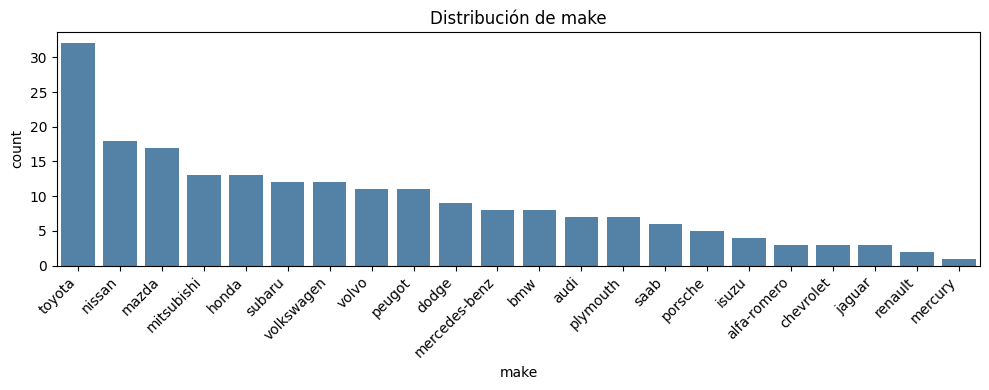

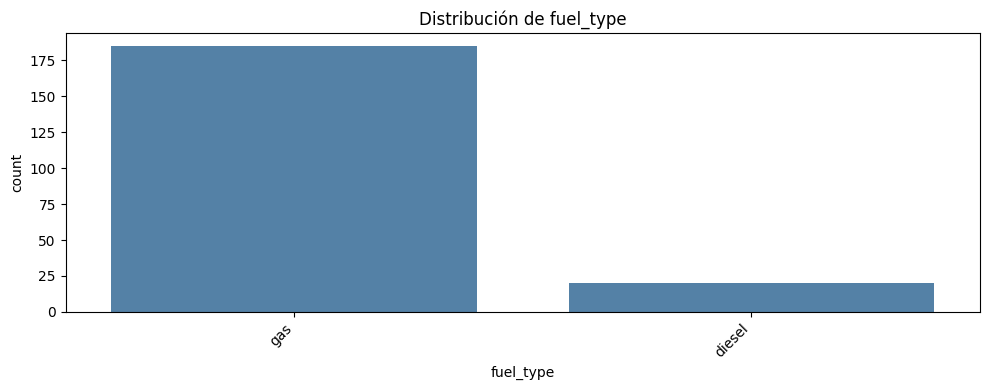

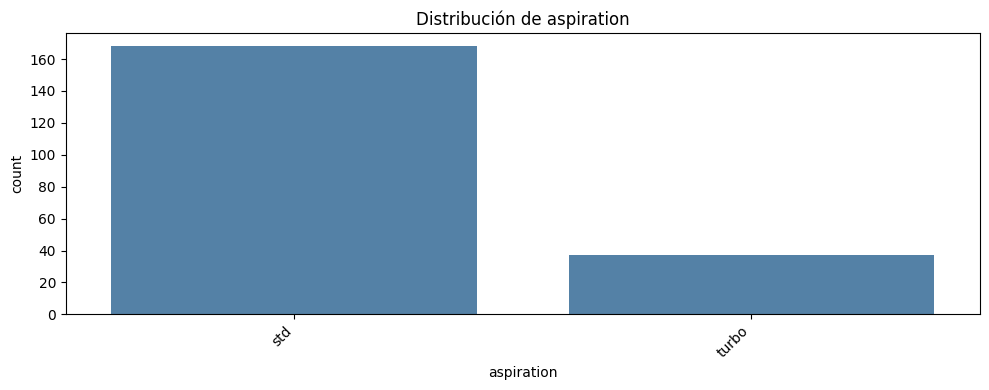

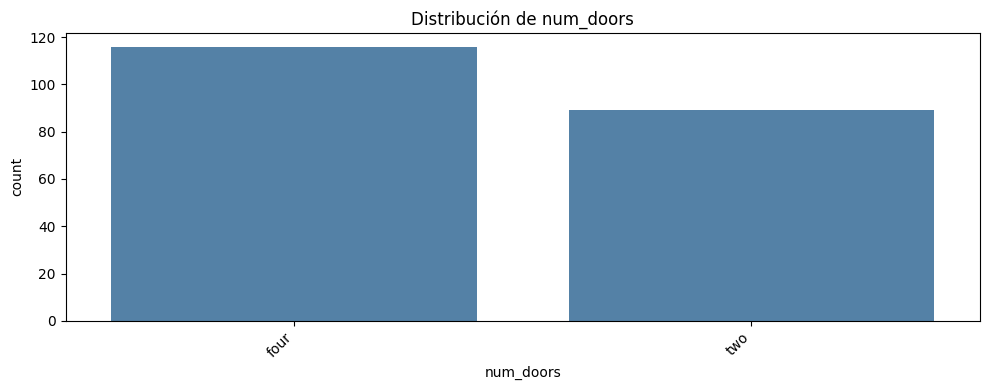

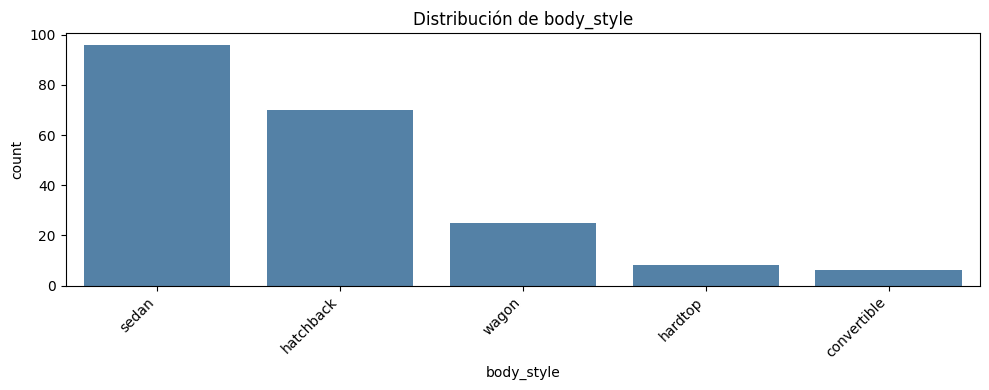

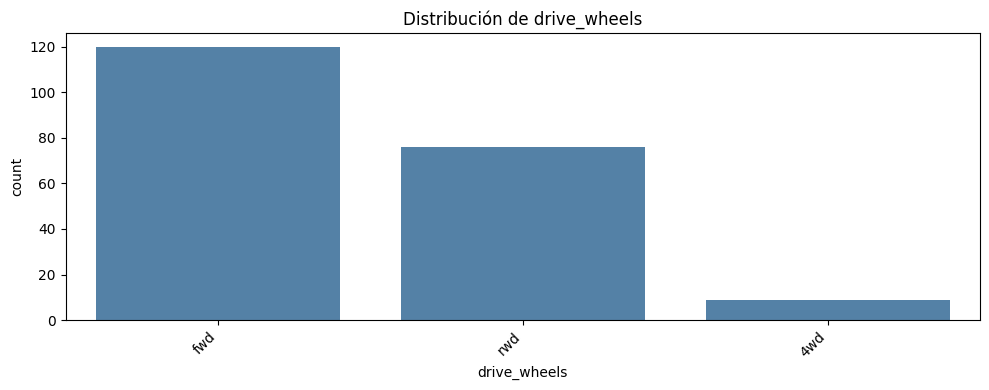

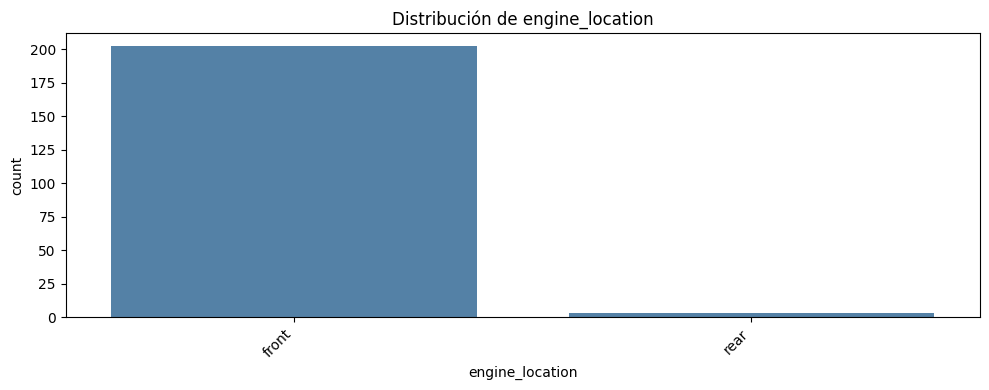

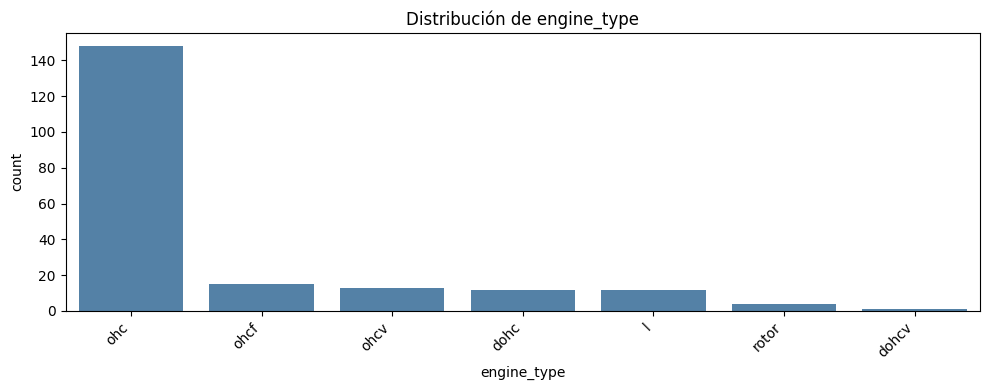

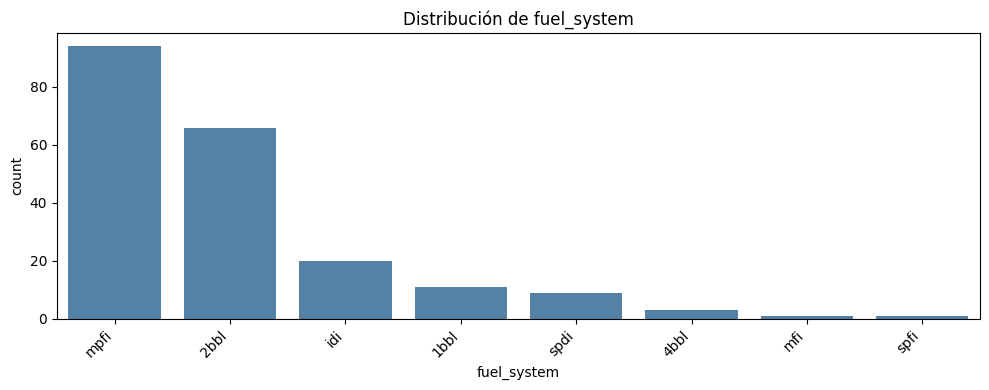

In [16]:
for col in cat_df.columns:
    plt.figure(figsize=(10, 4))

    orden = cars_df[col].value_counts().index

    sns.countplot(
        data=cars_df,
        x=col,
        order=orden,
        color='steelblue'
    )

    plt.title(f'Distribución de {col}')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# Análisis exploratorio de datos (bivariado)

3. Genera algunos gráficos bivariados para familiarizarte con el conjunto de datos:
* Gráfico de barras apiladas normalizadas que muestra la distribución de los tipos de tracción para cada fabricante.
* Diagrama de cajas para visualizar cómo se distribuye el precio de los automóviles según el estilo de carrocería. Esto permitirá comparar la mediana, los cuartiles y la presencia de valores atípicos entre los diferentes tipos de carrocería.
* Gráfico de barras que muestre los 10 automóviles más caros, ordenados de mayor a menor precio, con cada barra diferenciada con color por fabricante.
* Diagrama de dispersión para explorar la relación entre el tamaño del motor y el precio de los automóviles. Diferencia con colores los puntos según el tipo de aspiración y con el tamaño de los puntos el número de puertas.

**Nota.** Debes incluir en cada gráfico una conclusión de lo observado.

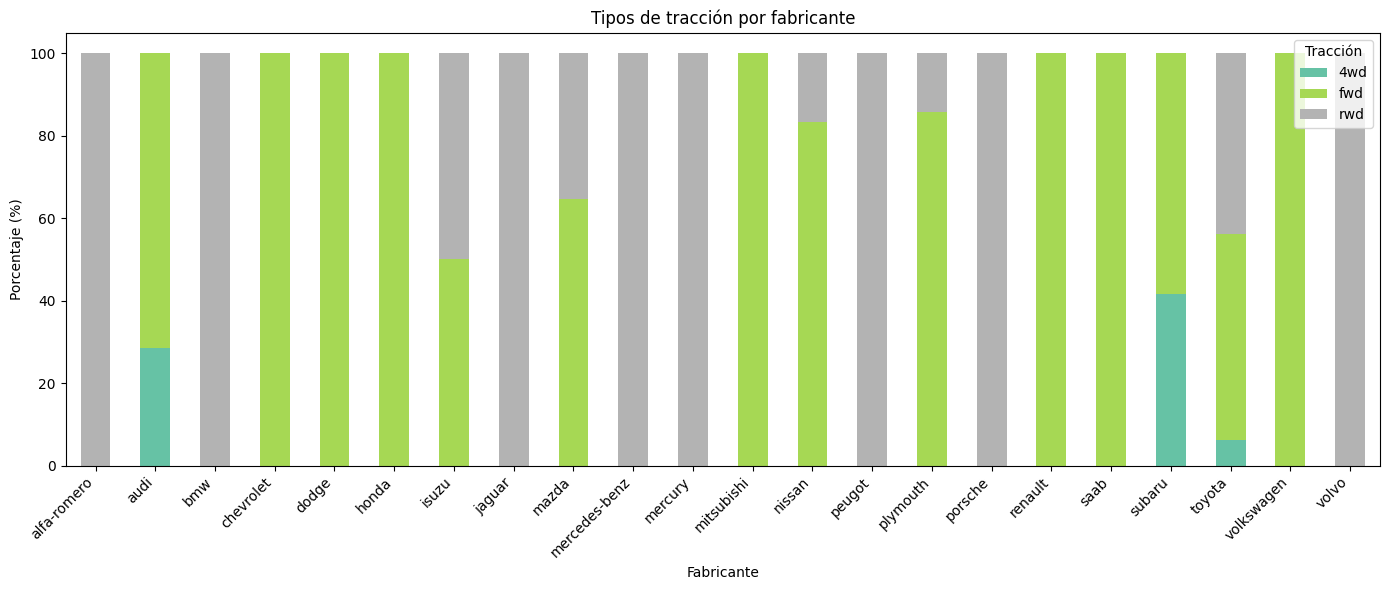

In [17]:
tabla = pd.crosstab(
    cars_df['make'],
    cars_df['drive_wheels'],
    normalize='index'
) * 100

tabla.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 6),
    colormap='Set2'
)

plt.title('Tipos de tracción por fabricante')
plt.xlabel('Fabricante')
plt.ylabel('Porcentaje (%)')
plt.legend(title='Tracción')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


El gráfico nos permite identificar qué fabricantes concentran sus modelos en los diferentes tipos de tracción:
* Tracción trasera:  Alfa-romero, BMW, Jaguar, Mercedes-Benz, Mercury,Peugot, Porshe y Volvo.
* Tracción delantera:  Chevrolet, Dodge, Honda, Mitsubishi, Nissan, Plymouth, Renault, Saab y Volkswagen.
* Tracción integral: Ningún fabricante concentra toda su fabricación en este tipo de tracción.  Unicamente se presenta en marcas como Audi, Subaru y Toyota.
* El único fabricante que tiene los tres tipos de tracción es Toyota.

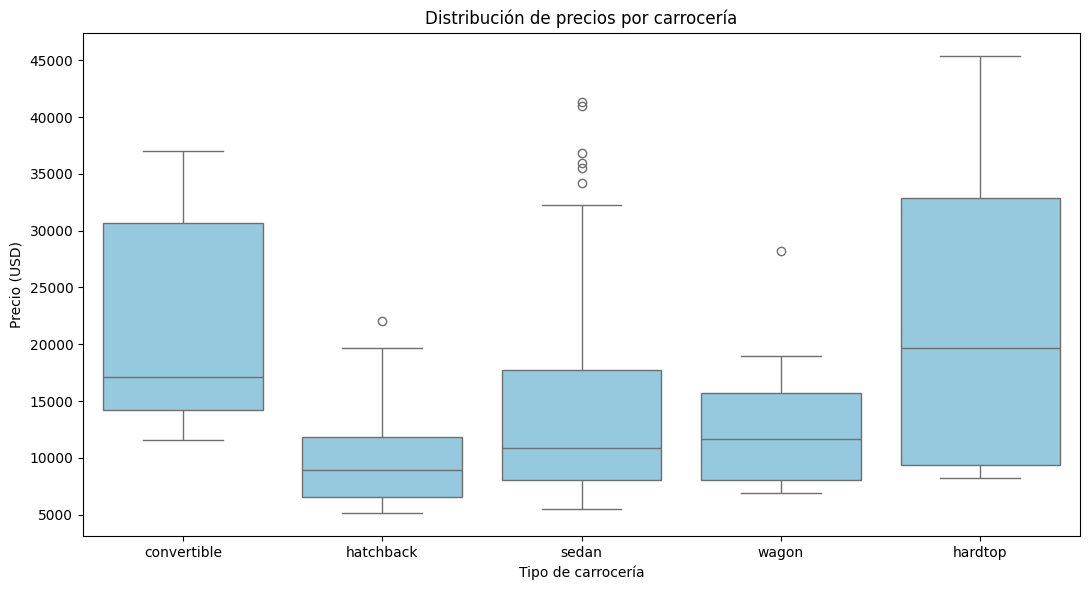

In [18]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=cars_df,
    x='body_style',
    y='price',
    color='skyblue'
)

plt.title('Distribución de precios por carrocería')
plt.xlabel('Tipo de carrocería')
plt.ylabel('Precio (USD)')
plt.tight_layout()
plt.show()

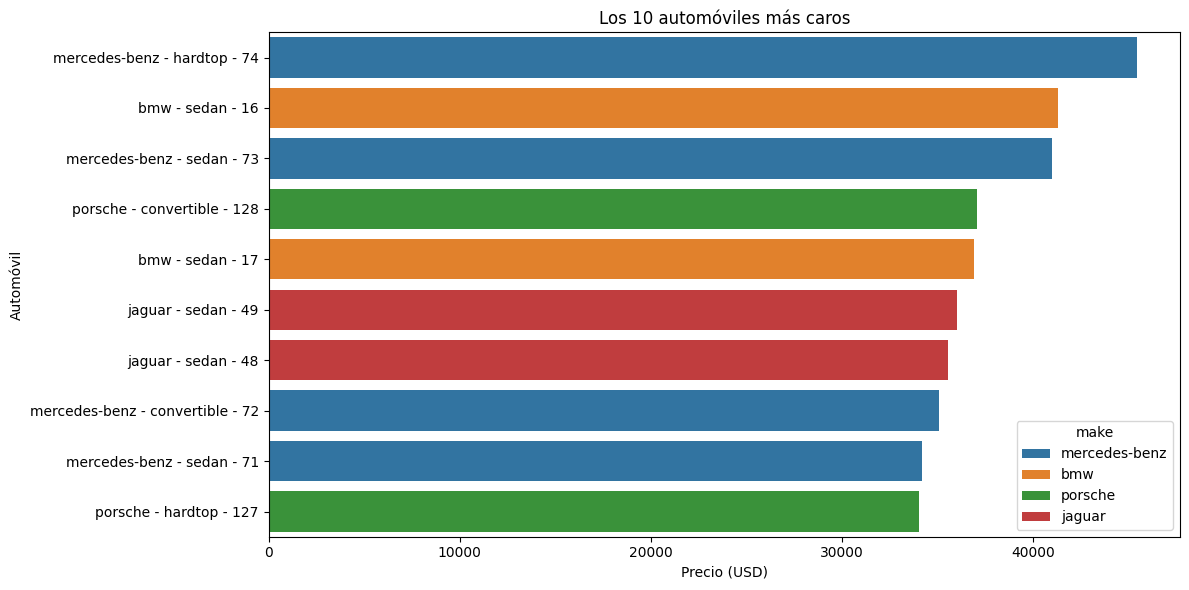

In [19]:
top10 = cars_df.nlargest(10, 'price').copy()

top10['auto'] = (
    top10['make'] + ' - ' +
    top10['body_style'] + ' - ' +
    top10.index.astype(str)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top10,
    x='price',
    y='auto',
    hue='make',
    dodge=False
)

plt.title('Los 10 automóviles más caros')
plt.xlabel('Precio (USD)')
plt.ylabel('Automóvil')
plt.tight_layout()
plt.show()

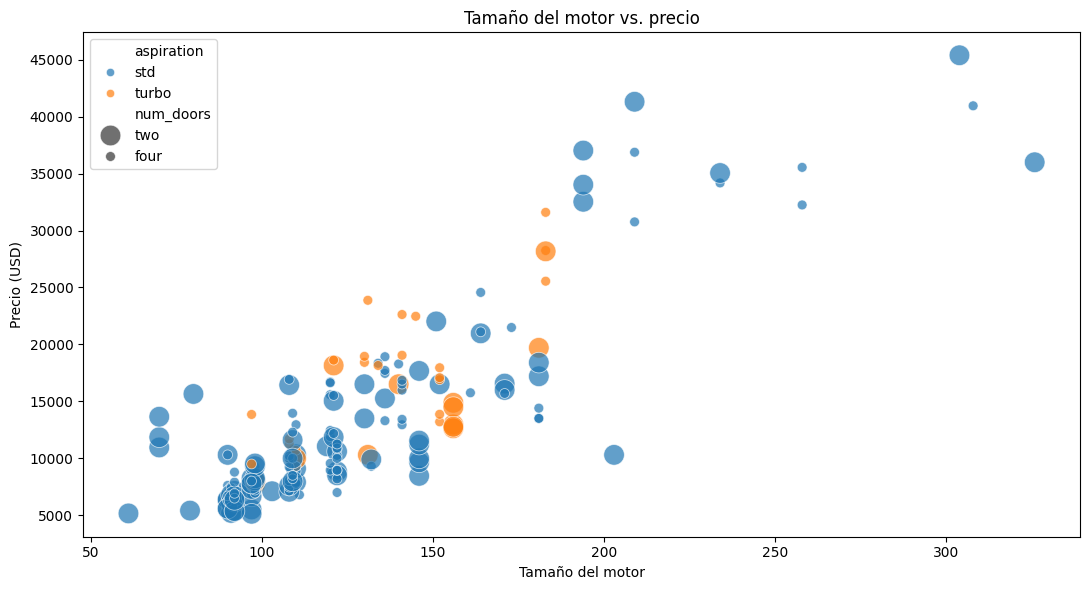

In [20]:
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=cars_df,
    x='engine_size',
    y='price',
    hue='aspiration',
    size='num_doors',
    sizes=(50, 220),
    alpha=0.7
)

plt.title('Tamaño del motor vs. precio')
plt.xlabel('Tamaño del motor')
plt.ylabel('Precio (USD)')
plt.tight_layout()
plt.show()

Observamos una asociación positiva entre tamaño del motor y precio, respaldada por una correlación de aproximadamente 0.86 en este conjunto de datos. Los automóviles con motores de mayor tamaño tienden a presentar precios superiores, aunque esta relación no demuestra causalidad.

4. Genera un mapa de calor de la matriz de correlación entre las variables numéricas del conjunto de datos, mostrando los valores de correlación en cada celda.
* ¿Cuáles son las tres variables más correlacionadas con el precio?

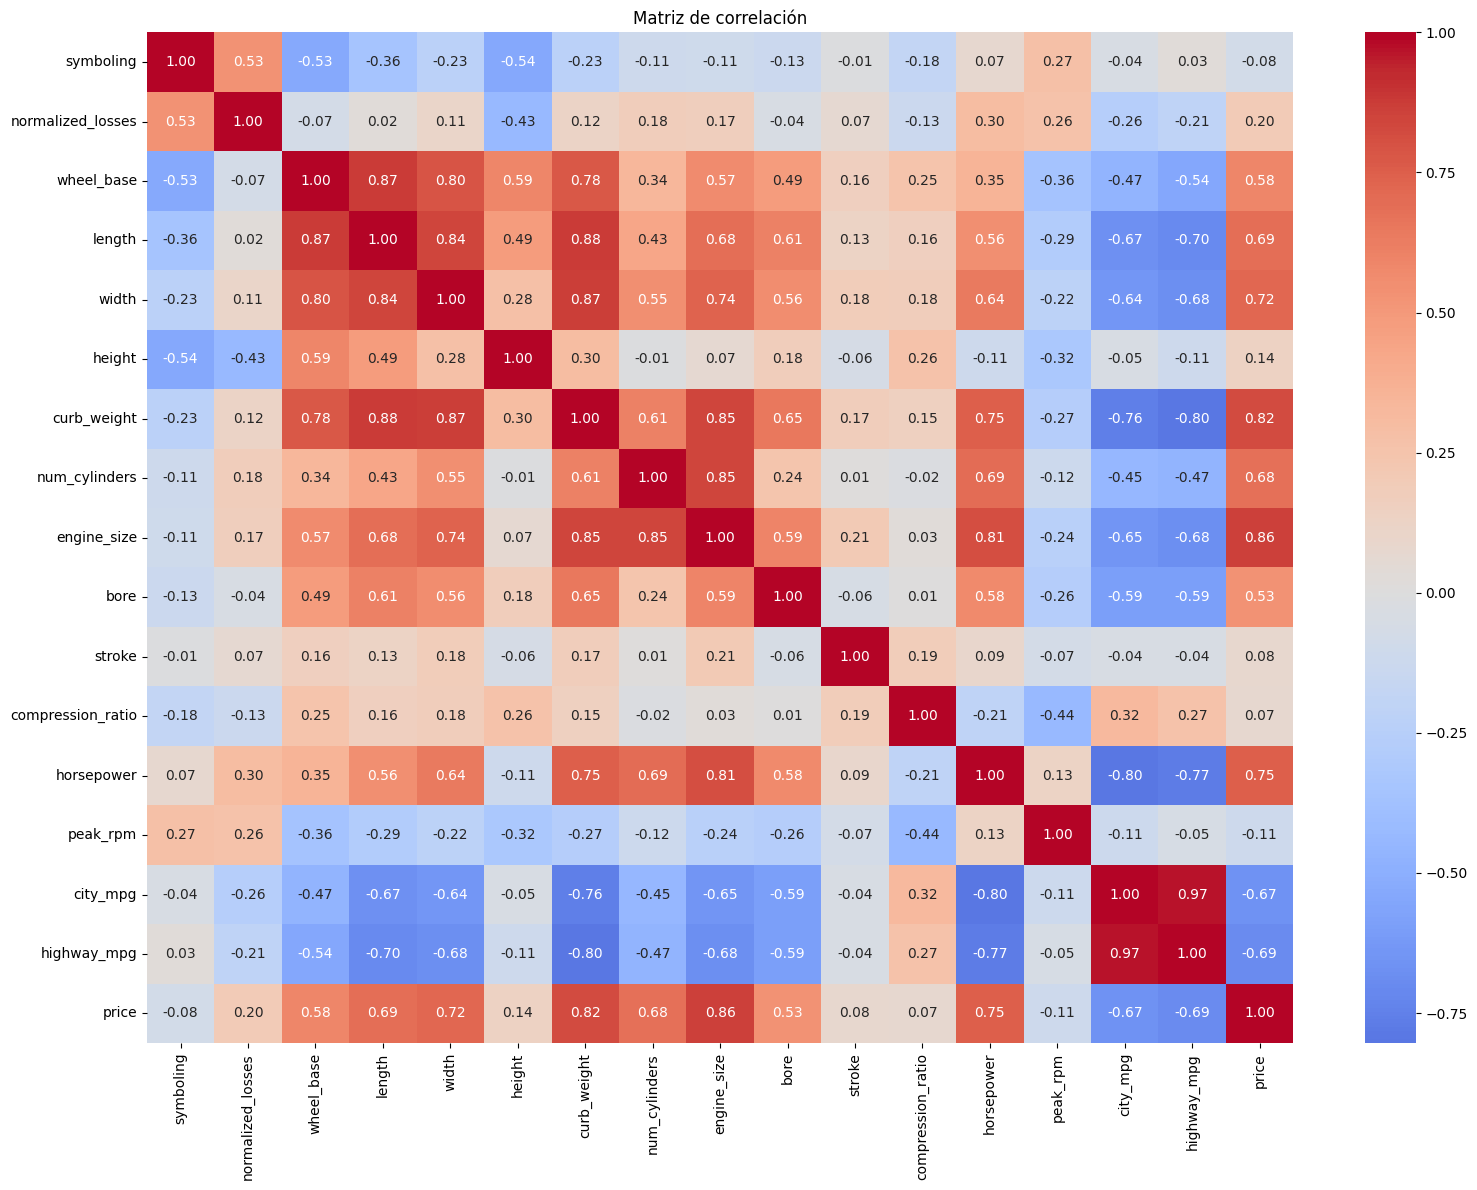

In [21]:
corr_matrix = cars_df.select_dtypes(
    include='number'
).corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()


In [22]:
correlacion_precio = (
    corr_matrix['price']
    .drop('price')
    .sort_values(ascending=False)
)

print(correlacion_precio.head(3))

engine_size    0.860343
curb_weight    0.819817
horsepower     0.749844
Name: price, dtype: float64


Las tres variables con mayor correlación positiva con el precio son engine_size, curb_weight y horsepower.

Esto indica que el tamaño del motor, el peso del automóvil y su potencia están fuertemente asociados con el precio.

En el análisis de correlación se observa que existen muchos pares de variables altamente correlacionadas, lo que puede afectar el desempeño de los modelos de regresión. PCA resulta útil no solo para reducir la dimensionalidad, sino también porque los componentes principales son ortogonales entre sí, es decir, tienen correlación cero, evitando problemas de multicolinealidad. Esto lo podrás comprobrar más adelante.

# Ingeniería de características

5. Realiza las siguientes operaciones de ingeniería de características en las variables numéricas:
* Considera `price` como la variable objetivo y guárdala en `y`. Separa los predictores numéricos en `X`. Con base en estos datos, ¿cuántos componentes principales se generarán al aplicar PCA?
* Aplica `SimpleImputer` sobre `X` para tratar los valores faltantes, justificando la estrategia de imputación seleccionada.
* Realiza el escalamiento del conjunto `X` ya imputado, para que todas las variables contribuyan equitativamente y ninguna domine el análisis por tener una escala mayor.

PCA está diseñado principalmente para variables numéricas y funciona encontrando combinaciones lineales de las variables originales que capturan la mayor varianza en los datos. Normalmente se recomienda eliminar las variables categóricas antes de aplicar PCA y luego concatenarlas nuevamente con los resultados de PCA si se desea.

In [24]:
# Primero separar los predictores de la variable objetivo

y = cars_df['price'].copy()

X = cars_df.select_dtypes(
    include='number'
).drop(columns=['price'])

print('Dimensiones de X:', X.shape)
print('Dimensiones de y:', y.shape)
print('Variables predictoras:')
print(X.columns.tolist())

Dimensiones de X: (205, 16)
Dimensiones de y: (205,)
Variables predictoras:
['symboling', 'normalized_losses', 'wheel_base', 'length', 'width', 'height', 'curb_weight', 'num_cylinders', 'engine_size', 'bore', 'stroke', 'compression_ratio', 'horsepower', 'peak_rpm', 'city_mpg', 'highway_mpg']


Excluimos la variable price de X porque es la variable que se desea predecir posteriormente

In [25]:
# Imputar los valores faltantes con la estrategia de la mediana ya que es menos sensibles a valores extremos.

y = cars_df['price'].copy()

X = cars_df.select_dtypes(
    include='number'
).drop(columns=['price'])

print('Dimensiones de X:', X.shape)
print('Dimensiones de y:', y.shape)
print('Variables predictoras:')
print(X.columns.tolist())

Dimensiones de X: (205, 16)
Dimensiones de y: (205,)
Variables predictoras:
['symboling', 'normalized_losses', 'wheel_base', 'length', 'width', 'height', 'curb_weight', 'num_cylinders', 'engine_size', 'bore', 'stroke', 'compression_ratio', 'horsepower', 'peak_rpm', 'city_mpg', 'highway_mpg']


In [27]:
# 1. Imputar los valores faltantes con la estrategia de la mediana
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

# 2. Estandarización de las variables
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_imputed),
    columns=X.columns,
    index=X.index
)

display(X_scaled.head())

,symboling,normalized_losses,wheel_base,length,width,height,curb_weight,num_cylinders,engine_size,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg
0,1.743470,-0.176503,-1.690772,-0.426521,-0.844782,-2.020417,-0.014566,-0.352887,0.074449,0.520489,-1.841345,-0.288349,0.173309,-0.264983,-0.646553,-0.546059
1,1.743470,-0.176503,-1.690772,-0.426521,-0.844782,-2.020417,-0.014566,-0.352887,0.074449,0.520489,-1.841345,-0.288349,0.173309,-0.264983,-0.646553,-0.546059
2,0.133509,-0.176503,-0.708596,-0.231513,-0.190566,-0.543527,0.514882,1.502032,0.604046,-2.403313,0.683683,-0.288349,1.263761,-0.264983,-0.953012,-0.691627
3,0.938490,1.367901,0.173698,0.207256,0.136542,0.235942,-0.420797,-0.352887,-0.431076,-0.515795,0.459947,-0.035973,-0.054925,0.785723,-0.186865,-0.109354
4,0.938490,1.367901,0.107110,0.207256,0.230001,0.235942,0.516807,0.574572,0.218885,-0.515795,0.459947,-0.540725,0.274747,0.785723,-1.106241,-1.273900


6. Aplica `PCA` a los datos escalados para proyectarlos en el nuevo espacio de vectores.
* Asigna nombres descriptivos a los componentes principales en el dataframe resultante, utilizando la convención PC1, PC2, PC3, y así sucesivamente.
* Genera un mapa de calor con la matriz de correlaciones de los componentes principales para verificar que sean independientes entre sí.

In [28]:
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

nombres_pc = [
    f'PC{i+1}' for i in range(X_pca.shape[1])
]

pca_df = pd.DataFrame(
    X_pca,
    columns=nombres_pc,
    index=X.index
)

display(pca_df.head())


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.288788,-1.088415,-0.347735,-0.474581,0.267610,-0.273617,0.362346,0.185204,0.003853
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.288788,-1.088415,-0.347735,-0.474581,0.267610,-0.273617,0.362346,0.185204,0.003853
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065,1.370499,-1.130802,-1.013703,0.502983,0.657052,0.174955,-0.008520,0.118635,-0.111688
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484,0.400032,0.293338,0.168137,0.039239,-0.022832,-0.078891,-0.391786,0.009265,0.053641
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900,0.870186,0.015429,-0.447054,-0.055376,-0.416053,-0.049431,0.079357,-0.198402,0.046303


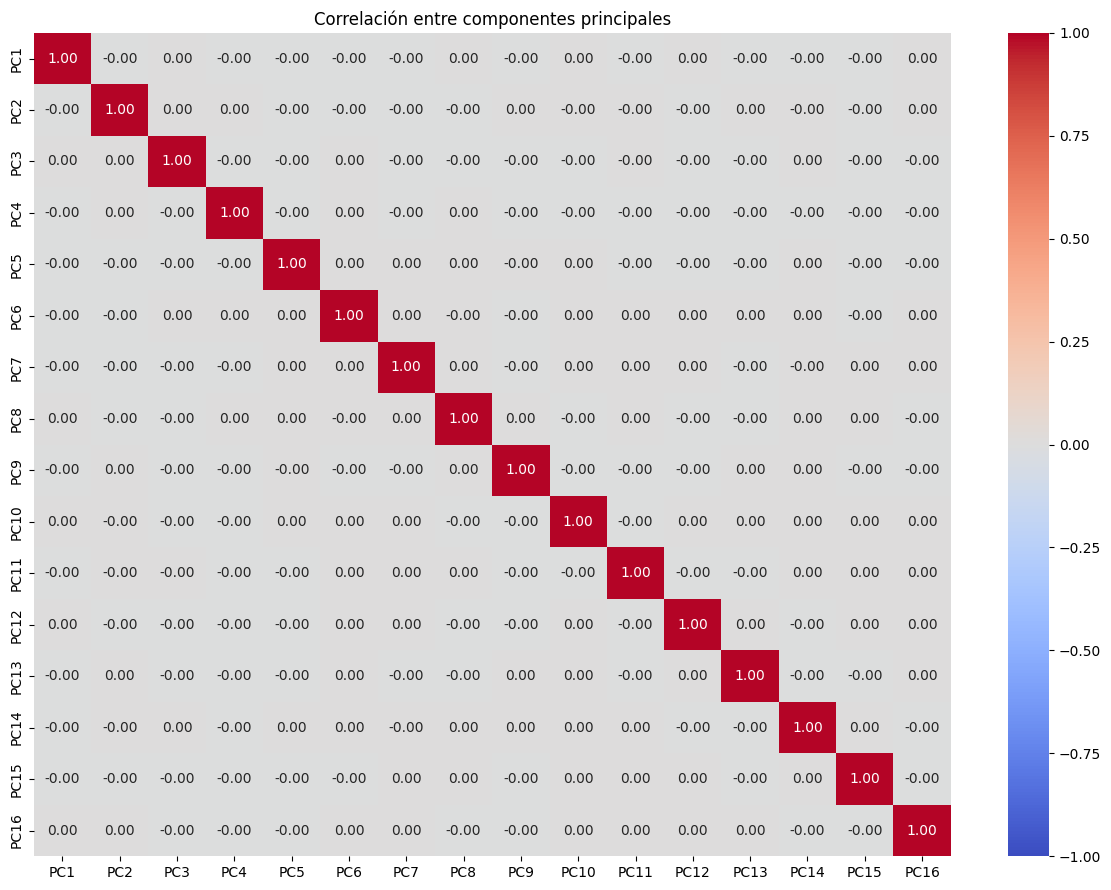

In [29]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    pca_df.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title('Correlación entre componentes principales')
plt.tight_layout()
plt.show()


7. Obtén el porcentaje de varianza explicada por cada componente.
* Grafica la curva de varianza acumulada para determinar el número mínimo de componentes principales que explican más del 90% de la varianza total.

In [30]:
varianza = pca.explained_variance_ratio_

varianza_acumulada = np.cumsum(varianza)

tabla_varianza = pd.DataFrame({
    'Componente': nombres_pc,
    'Varianza explicada (%)': varianza * 100,
    'Varianza acumulada (%)': varianza_acumulada * 100
})

display(tabla_varianza.round(2))

,Componente,Varianza explicada (%),Varianza acumulada (%)
0,PC1,44.55,44.55
1,PC2,17.93,62.48
2,PC3,8.58,71.05
3,PC4,6.44,77.49
4,PC5,5.74,83.23
5,PC6,4.78,88.01
6,PC7,3.25,91.26
7,PC8,2.73,93.98
8,PC9,1.94,95.92
9,PC10,1.55,97.48


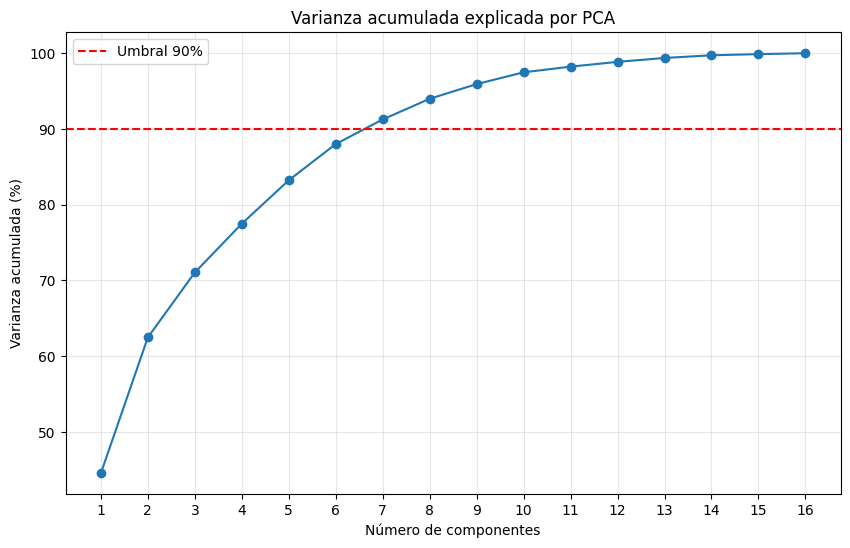

In [31]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(varianza_acumulada) + 1),
    varianza_acumulada * 100,
    marker='o'
)

plt.axhline(
    y=90,
    color='red',
    linestyle='--',
    label='Umbral 90%'
)

plt.xlabel('Número de componentes')
plt.ylabel('Varianza acumulada (%)')
plt.title('Varianza acumulada explicada por PCA')
plt.xticks(range(1, len(varianza_acumulada) + 1))
plt.grid(alpha=0.3)
plt.legend()
plt.show()


In [32]:
n_componentes = (
    np.searchsorted(varianza_acumulada, 0.90) + 1
)

print('Componentes necesarios:', n_componentes)

print(
    'Varianza conservada:',
    round(varianza_acumulada[n_componentes - 1] * 100, 2),
    '%'
)

Componentes necesarios: 7
Varianza conservada: 91.26 %


Se requieren siete componentes principales para explicar más del 90% de la varianza.

Esta reducción disminuye la dimensionalidad de los predictores numéricos en un 56.25%, manteniendo aproximadamente el 91.26% de su variabilidad.

8. Imprime la información de los componentes seleccionados (cargas o pesos de las variables originales) para interpretar qué variables contribuyen más a cada componente principal.
* Dibuja un diagrama de barras que muestre qué variables originales aportan más al primer componente principal (PC1), para visualizar su influencia relativa.

In [33]:
cargas = pd.DataFrame(
    pca.components_[:n_componentes].T,
    index=X.columns,
    columns=nombres_pc[:n_componentes]
)

display(cargas.round(3))

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
symboling,-0.097,-0.403,0.265,-0.072,-0.366,0.173,0.128
normalized_losses,0.016,-0.331,0.308,-0.343,-0.376,-0.492,-0.323
wheel_base,0.298,0.265,-0.029,-0.228,-0.004,-0.183,-0.106
length,0.338,0.139,-0.044,-0.194,-0.074,-0.082,-0.009
width,0.334,0.055,0.109,-0.098,-0.016,-0.107,0.140
height,0.114,0.422,-0.282,-0.186,-0.017,-0.214,-0.003
curb_weight,0.362,0.022,0.080,-0.025,-0.042,-0.014,0.061
num_cylinders,0.245,-0.114,0.177,0.552,0.237,-0.354,-0.068
engine_size,0.330,-0.082,0.199,0.296,0.109,0.016,-0.073
bore,0.263,0.003,-0.138,0.041,-0.373,0.512,0.126


In [34]:
pesos_pc1 = cargas['PC1'].sort_values(
    key=abs,
    ascending=False
)

display(pesos_pc1)

,PC1
curb_weight,0.361949
length,0.337567
width,0.334154
engine_size,0.330140
highway_mpg,-0.317429
city_mpg,-0.305762
horsepower,0.298459
wheel_base,0.297827
bore,0.262714
num_cylinders,0.245179


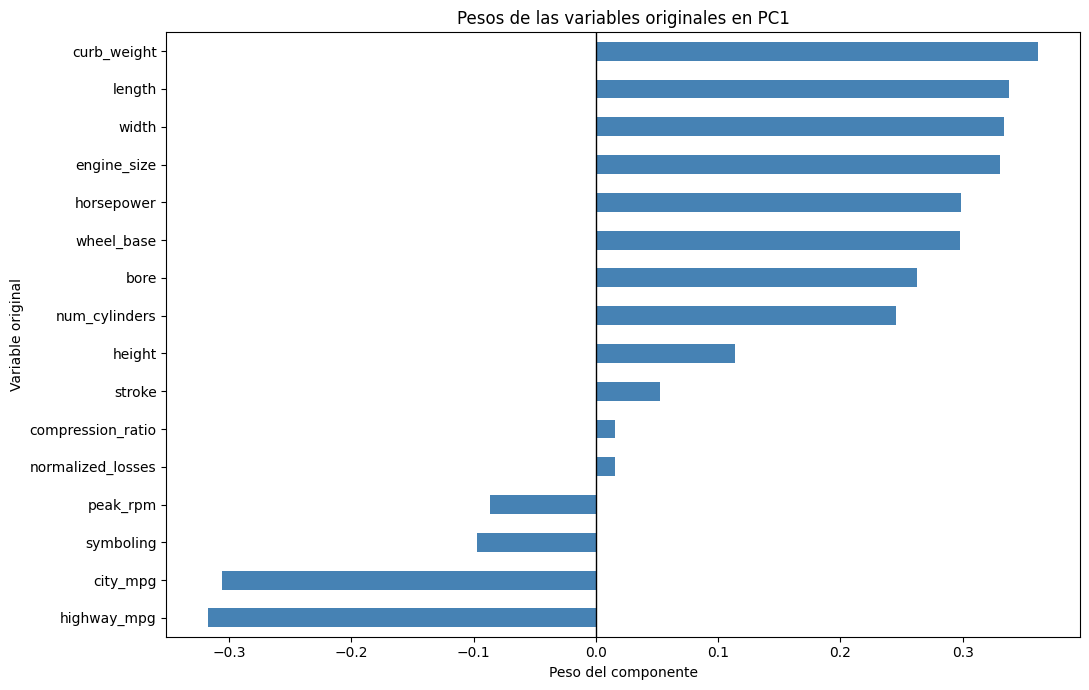

In [35]:
plt.figure(figsize=(11, 7))

pesos_pc1.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.axvline(0, color='black', linewidth=1)

plt.title('Pesos de las variables originales en PC1')
plt.xlabel('Peso del componente')
plt.ylabel('Variable original')
plt.tight_layout()
plt.show()


Las variables con mayor peso positivo incluyen el peso, la longitud, el ancho y el tamaño del motor. Por el contrario, el rendimiento de combustible en ciudad y carretera tiene pesos negativos relevantes.

Esto sugiere que PC1 representa principalmente una dimensión asociada al tamaño, peso y capacidad mecánica del automóvil, en contraste con su eficiencia de combustible.

Los automóviles con valores altos de PC1 tienden a ser más grandes, pesados y potentes, mientras que aquellos con valores bajos tienden a ser más eficientes en combustible.

In [36]:
for pc in cargas.columns:
    print(f'\nVariables más importantes de {pc}')

    importantes = cargas[pc].sort_values(
        key=abs,
        ascending=False
    ).head(5)

    print(importantes.round(3))



Variables más importantes de PC1
curb_weight    0.362
length         0.338
width          0.334
engine_size    0.330
highway_mpg   -0.317
Name: PC1, dtype: float64

Variables más importantes de PC2
height               0.422
symboling           -0.403
peak_rpm            -0.364
compression_ratio    0.361
normalized_losses   -0.331
Name: PC2, dtype: float64

Variables más importantes de PC3
stroke               0.512
compression_ratio    0.490
normalized_losses    0.308
height              -0.282
symboling            0.265
Name: PC3, dtype: float64

Variables más importantes de PC4
num_cylinders        0.552
stroke              -0.431
normalized_losses   -0.343
engine_size          0.296
peak_rpm            -0.289
Name: PC4, dtype: float64

Variables más importantes de PC5
stroke               0.572
normalized_losses   -0.376
bore                -0.373
symboling           -0.366
peak_rpm             0.341
Name: PC5, dtype: float64

Variables más importantes de PC6
bore                 

9. Codifica las variables categóricas mediante *One-Hot Encoding* y utiliza el parámetro `drop='first'` para evitar problemas de multicolinealidad entre las variables dummy generadas.

In [37]:
X_cat = cars_df.select_dtypes(
    include='object'
).copy()

print(X_cat.columns.tolist())
print(X_cat.shape)

['make', 'fuel_type', 'aspiration', 'num_doors', 'body_style', 'drive_wheels', 'engine_location', 'engine_type', 'fuel_system']
(205, 9)


In [38]:
encoder = OneHotEncoder(
    drop='first',
    handle_unknown='ignore',
    sparse_output=False
)

X_cat_encoded = encoder.fit_transform(X_cat)

nombres_categorias = encoder.get_feature_names_out(
    X_cat.columns
)

cat_encoded_df = pd.DataFrame(
    X_cat_encoded,
    columns=nombres_categorias,
    index=cars_df.index
)

display(cat_encoded_df.head())
print(cat_encoded_df.shape)


,make_audi,make_bmw,make_chevrolet,make_dodge,make_honda,make_isuzu,make_jaguar,make_mazda,make_mercedes-benz,make_mercury,...,engine_type_ohcf,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


(205, 44)


10. Conjunta, en un dataframe, las valores proyectados en los componentes seleccionados (mínimo), las transformaciones obtenidas de las variables categóricas y la variable de salida.
* Almacena el dataframe resultante en archivo.

In [39]:
pca_selected_df = pca_df.iloc[
    :, :n_componentes
].copy()

display(pca_selected_df.head())

print(pca_selected_df.shape)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900


(205, 7)


In [40]:
cars_final_df = pd.concat(
    [
        pca_selected_df,
        cat_encoded_df,
        y.rename('price')
    ],
    axis=1
)

print('Dimensiones finales:', cars_final_df.shape)

display(cars_final_df.head())


Dimensiones finales: (205, 52)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,make_audi,make_bmw,make_chevrolet,...,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi,price
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13495
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,16500
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,16500
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13950
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,17450


In [41]:
print('Valores faltantes:')
print(cars_final_df.isnull().sum().sum())

print('\nRegistros duplicados:')
print(cars_final_df.duplicated().sum())

print('\nTipos de datos:')
cars_final_df.info()

Valores faltantes:
0

Registros duplicados:
0

Tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 52 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   PC1                   205 non-null    float64
 1   PC2                   205 non-null    float64
 2   PC3                   205 non-null    float64
 3   PC4                   205 non-null    float64
 4   PC5                   205 non-null    float64
 5   PC6                   205 non-null    float64
 6   PC7                   205 non-null    float64
 7   make_audi             205 non-null    float64
 8   make_bmw              205 non-null    float64
 9   make_chevrolet        205 non-null    float64
 10  make_dodge            205 non-null    float64
 11  make_honda            205 non-null    float64
 12  make_isuzu            205 non-null    float64
 13  make_jaguar           205 non-null    float64
 14  make_mazda 

In [42]:
cars_final_df.to_csv(
    'automobile_dataset_PCA_final.csv',
    index=False
)

print('Archivo guardado correctamente')


Archivo guardado correctamente


In [43]:
from google.colab import files

files.download('automobile_dataset_PCA_final.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---